# Progetto: Analisi Prezzi Laptop — Machine Learning & Data Analysis
Questo progetto applica tecniche di pulizia dati, feature engineering ed esperimenti di regressione per prevedere il prezzo dei laptop a partire da specifiche tecniche e brand.

- Autore: Billal Nadi
- Dataset: Laptop-Price.csv
- Obiettivo: costruire modelli predittivi, valutarne le performance e interpretare le feature più influenti.

## 1. Setup e Caricamento Dati

Iniziamo configurando l'ambiente di lavoro e importando le librerie fondamentali per l'analisi e il training. Carichiamo il dataset per ispezionare la struttura iniziale, le dimensioni e le tipologie di dati rilevate automaticamente da pandas.

In [1]:
# Setup ambiente e import
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

SEED = 42
DATA_PATH = "Laptop-Price.csv"

sns.set_theme(style="whitegrid", context="notebook")

df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape}")
display(df.head())
display(df.info())

Shape: (1146, 18)


,Company,Product,TypeName,Inches,ScreenResolution,Ram,OpSys,Cpu Brand,Cpu Model,Cpu Rate,SSD,HDD,Flash Storage,Hybrid,Gpu Brand,Gpu Model,Unnamed: 16,Price_euros
0,HP,250 G6,Notebook,15.6,Full HD 1920x1080,8GB,No OS,Intel,Core i5 7200U,2.5GHz,256,0,0,0,Intel,HD Graphics 620,NaN,575.0
1,Acer,Aspire 3,Notebook,15.6,1366x768,4GB,Windows 10,AMD,A9-Series 9420,3GHz,0,500,0,0,AMD,Radeon R5,NaN,400.0
2,Asus,ZenBook UX430UN,Ultrabook,14.0,Full HD 1920x1080,16GB,Windows 10,Intel,Core i7 8550U,1.8GHz,512,0,0,0,Nvidia,GeForce MX150,NaN,1495.0
3,Acer,Swift 3,Ultrabook,14.0,IPS Panel Full HD 1920x1080,8GB,Windows 10,Intel,Core i5 8250U,1.6GHz,256,0,0,0,Intel,UHD Graphics 620,NaN,770.0
4,HP,250 G6,Notebook,15.6,1366x768,4GB,No OS,Intel,Core i5 7200U,2.5GHz,0,500,0,0,Intel,HD Graphics 620,NaN,393.9


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1146 entries, 0 to 1145
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Company           1146 non-null   object 
 1   Product           1146 non-null   object 
 2   TypeName          1146 non-null   object 
 3   Inches            1146 non-null   float64
 4   ScreenResolution  1146 non-null   object 
 5   Ram               1146 non-null   object 
 6   OpSys             1146 non-null   object 
 7   Cpu Brand         1146 non-null   object 
 8   Cpu Model         1146 non-null   object 
 9   Cpu Rate          1146 non-null   object 
 10  SSD               1146 non-null   int64  
 11  HDD               1146 non-null   int64  
 12  Flash Storage     1146 non-null   int64  
 13  Hybrid            1146 non-null   int64  
 14  Gpu Brand         1146 non-null   object 
 15  Gpu Model         1146 non-null   object 
 16  Unnamed: 16       0 non-null      float64


None

## 2. Data Cleaning e Type Casting

Dall'ispezione iniziale del dataset emergono alcuni problemi strutturali da risolvere prima dell'analisi:

* **Feature inutili**: La colonna `Unnamed: 16` risulta completamente vuota (0 valori non nulli) e va rimossa.
* **Formato dati errato**: Le colonne `Ram` e `Cpu Rate` sono salvate come stringhe a causa delle unità di misura ("GB", "GHz").

Nella cella seguente, procediamo alla rimozione della colonna superflua e alla conversione di queste feature in valori numerici, gestendo eventuali valori mancanti tramite l'imputazione con la mediana per garantire la robustezza del dato.

In [2]:
# Pulizia dati di base
if 'Unnamed: 16' in df.columns:
    df = df.drop(columns=['Unnamed: 16'])

# Ram: estrae il numero e converte in int
df['Ram'] = df['Ram'].str.replace('GB', '', regex=False)
df['Ram'] = pd.to_numeric(df['Ram'], errors='coerce').astype('Int64')
df['Ram'] = df['Ram'].fillna(df['Ram'].median()).astype(int)

# Cpu Rate: rimuove 'GHz' e converte in float
df['Cpu Rate'] = df['Cpu Rate'].str.replace('GHz', '', regex=False)
df['Cpu Rate'] = pd.to_numeric(df['Cpu Rate'], errors='coerce')
df['Cpu Rate'] = df['Cpu Rate'].fillna(df['Cpu Rate'].median())

## 3. Feature Extraction: Risoluzione Schermo

La colonna `ScreenResolution` contiene informazioni testuali complesse che includono la risoluzione del display. Per rendere questi dati utilizzabili dai modelli, è necessario isolare i valori numerici di larghezza () e altezza ().

Nella cella seguente, utilizziamo un'espressione regolare per estrarre queste dimensioni e convertirle in formato numerico.

In [3]:
# Estrazione robusta di X_res e Y_res dalla risoluzione schermo
resolution = df['ScreenResolution'].str.extract(r'(?i)(\d+)\s*x\s*(\d+)')
df['X_res'] = pd.to_numeric(resolution[0], errors='coerce')
df['Y_res'] = pd.to_numeric(resolution[1], errors='coerce')

df.head()

,Company,Product,TypeName,Inches,ScreenResolution,Ram,OpSys,Cpu Brand,Cpu Model,Cpu Rate,SSD,HDD,Flash Storage,Hybrid,Gpu Brand,Gpu Model,Price_euros,X_res,Y_res
0,HP,250 G6,Notebook,15.6,Full HD 1920x1080,8,No OS,Intel,Core i5 7200U,2.5,256,0,0,0,Intel,HD Graphics 620,575.0,1920,1080
1,Acer,Aspire 3,Notebook,15.6,1366x768,4,Windows 10,AMD,A9-Series 9420,3.0,0,500,0,0,AMD,Radeon R5,400.0,1366,768
2,Asus,ZenBook UX430UN,Ultrabook,14.0,Full HD 1920x1080,16,Windows 10,Intel,Core i7 8550U,1.8,512,0,0,0,Nvidia,GeForce MX150,1495.0,1920,1080
3,Acer,Swift 3,Ultrabook,14.0,IPS Panel Full HD 1920x1080,8,Windows 10,Intel,Core i5 8250U,1.6,256,0,0,0,Intel,UHD Graphics 620,770.0,1920,1080
4,HP,250 G6,Notebook,15.6,1366x768,4,No OS,Intel,Core i5 7200U,2.5,0,500,0,0,Intel,HD Graphics 620,393.9,1366,768


## 4. Analisi della Distribuzione del Prezzo

Prima di procedere con la modellazione, analizziamo come si distribuiscono i prezzi nel dataset. Questo ci permette di identificare la fascia di prezzo più comune e la presenza di eventuali outlier (laptop di estremo lusso) che potrebbero influenzare la media degli errori del modello.

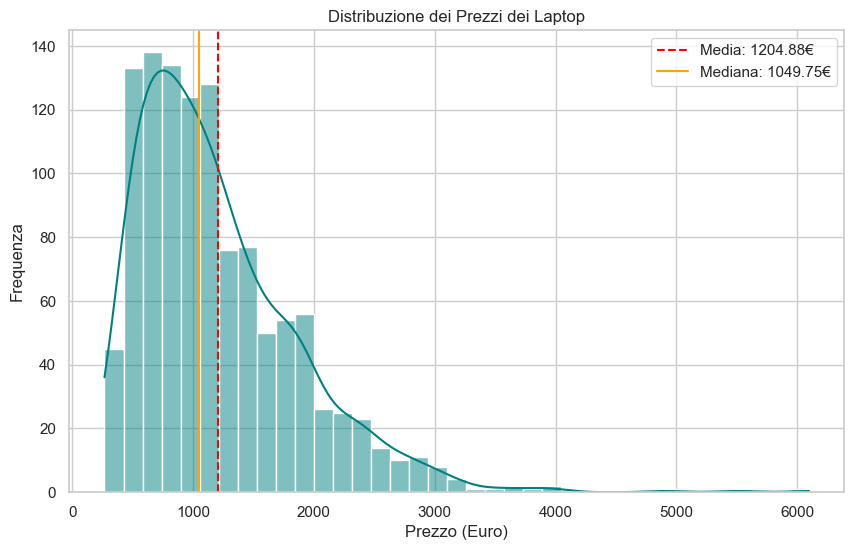

Prezzo Medio: 1204.88€
Prezzo Mediano: 1049.75€
Prezzo Minimo: 265.00€
Prezzo Massimo: 6099.00€


In [4]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Price_euros'], kde=True, color='teal')
plt.axvline(df['Price_euros'].mean(), color='red', linestyle='--', label=f"Media: {df['Price_euros'].mean():.2f}€")
plt.axvline(df['Price_euros'].median(), color='orange', linestyle='-', label=f"Mediana: {df['Price_euros'].median():.2f}€")

plt.title('Distribuzione dei Prezzi dei Laptop')
plt.xlabel('Prezzo (Euro)')
plt.ylabel('Frequenza')
plt.legend()
plt.show()

print(f"Prezzo Medio: {df['Price_euros'].mean():.2f}€")
print(f"Prezzo Mediano: {df['Price_euros'].median():.2f}€")
print(f"Prezzo Minimo: {df['Price_euros'].min():.2f}€")
print(f"Prezzo Massimo: {df['Price_euros'].max():.2f}€")

## 5. Analisi del Prezzo per Brand

I dati sulla distribuzione mostrano un prezzo medio di circa 1204.88 euro con una coda lunga verso i  ( 6099.00 euro ), confermando che il mercato include sia prodotti entry-level che workstation di lusso.

Dato che il brand è uno dei principali driver del valore percepito e del costo, analizziamo come varia il prezzo medio per ogni produttore. Questo ci permette di identificare quali aziende si posizionano nella fascia premium e quali in quella economica.

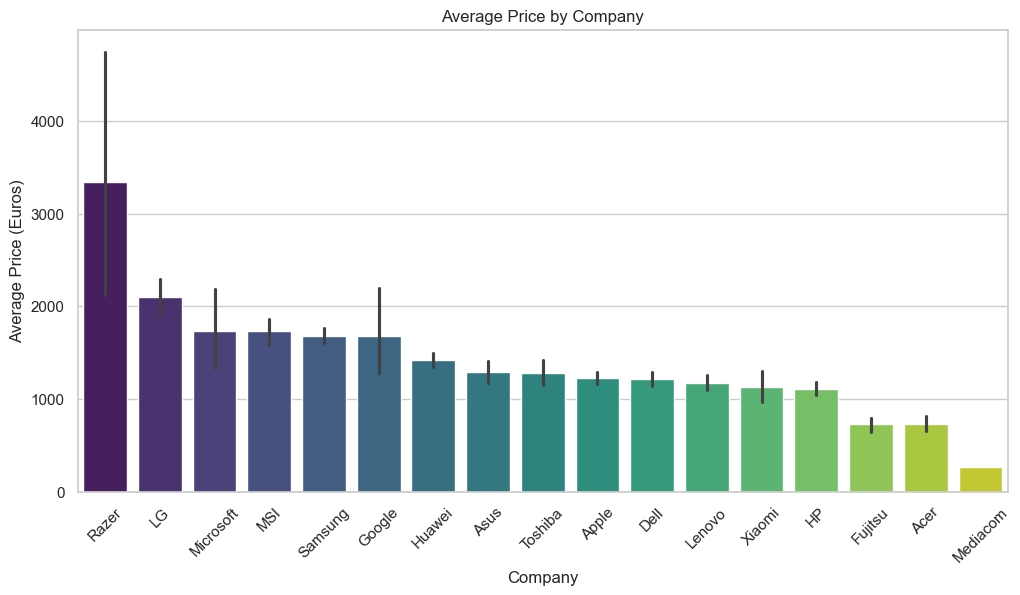

In [5]:
plt.figure(figsize=(12, 6))

# Calculate average price and sort for better visualization
brand_order = df.groupby('Company')['Price_euros'].mean().sort_values(ascending=False).index

sns.barplot(x='Company', y='Price_euros', data=df, order=brand_order, palette='viridis')
plt.xticks(rotation=45)
plt.title('Average Price by Company')
plt.xlabel('Company')
plt.ylabel('Average Price (Euros)')
plt.show()

## 6. Analisi dei Brand e Posizionamento

Dall'analisi grafica emerge una netta gerarchia di mercato:

* **Segmento High-End**: **Razer** si distingue con il prezzo medio più elevato (oltre 3000€), caratterizzato però da un'altissima variabilità (barra di errore estesa), segno di configurazioni hardware estremamente diversificate o modelli "flagship" molto costosi. Seguono **LG** e **Microsoft** nella fascia premium.
* **I Giganti del Mercato**: Brand come **Dell**, **Lenovo** e **HP** mostrano medie di prezzo stabili e molto simili tra loro (tra 1000€ e 1300€), confermando un'offerta massificata che copre tutte le fasce, ma con un baricentro sulla fascia media.
* **Entry-Level**: **Acer** e **Mediacom** rappresentano le opzioni più economiche, con quest'ultima che si posiziona costantemente sotto la soglia dei 500€.

## 7. Analisi del Prezzo per Tipologia (TypeName)

Il brand non è l'unico fattore determinante; la destinazione d'uso del laptop (Gaming, Workstation, Ultrabook) definisce i componenti interni e, di conseguenza, il prezzo. Utilizziamo un **boxplot** per visualizzare la distribuzione dei prezzi per categoria, identificando dove si concentrano i modelli più costosi e dove risiedono gli outlier.

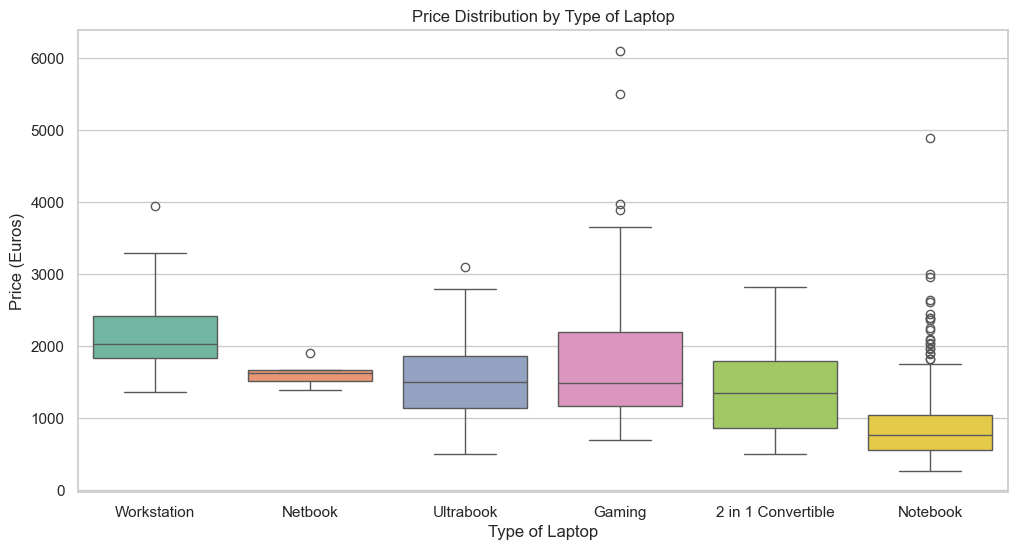

In [6]:
plt.figure(figsize=(12, 6))

type_order = df.groupby('TypeName')['Price_euros'].median().sort_values(ascending=False).index

sns.boxplot(x='TypeName', y='Price_euros', data=df, order=type_order, palette='Set2')
plt.title('Price Distribution by Type of Laptop')
plt.xlabel('Type of Laptop')
plt.ylabel('Price (Euros)')
plt.show()

I grafici precedenti mostrano chiaramente come il mercato sia segmentato sia per produttore che per destinazione d'uso:

* **Posizionamento Brand**: **Razer** domina la fascia altissima, ma con una varianza enorme che suggerisce la presenza di modelli "estremi". **LG**, **Microsoft** e **MSI** si confermano brand premium. Al contrario, **Acer** e **Mediacom** presidiano la fascia entry-level con prezzi medi molto contenuti.
* **Specializzazione per Tipologia**: Le **Workstation** hanno il prezzo mediano più alto e una varianza ridotta, indicando un costo base elevato per l'hardware professionale. I laptop da **Gaming** mostrano invece gli outlier più estremi (superando i 6000€), evidenziando come configurazioni spinte possano far lievitare il prezzo vertiginosamente. I **Notebook** classici rimangono la categoria più economica e popolata.

## 8. Impatto di RAM e SSD sul Prezzo

Dopo aver visto l'influenza del brand e della categoria, passiamo all'analisi dei componenti tecnici. RAM e SSD sono solitamente i driver principali del costo hardware. Utilizzeremo dei grafici a barre per osservare come il prezzo medio scali all'aumentare della memoria e dello storage veloce.

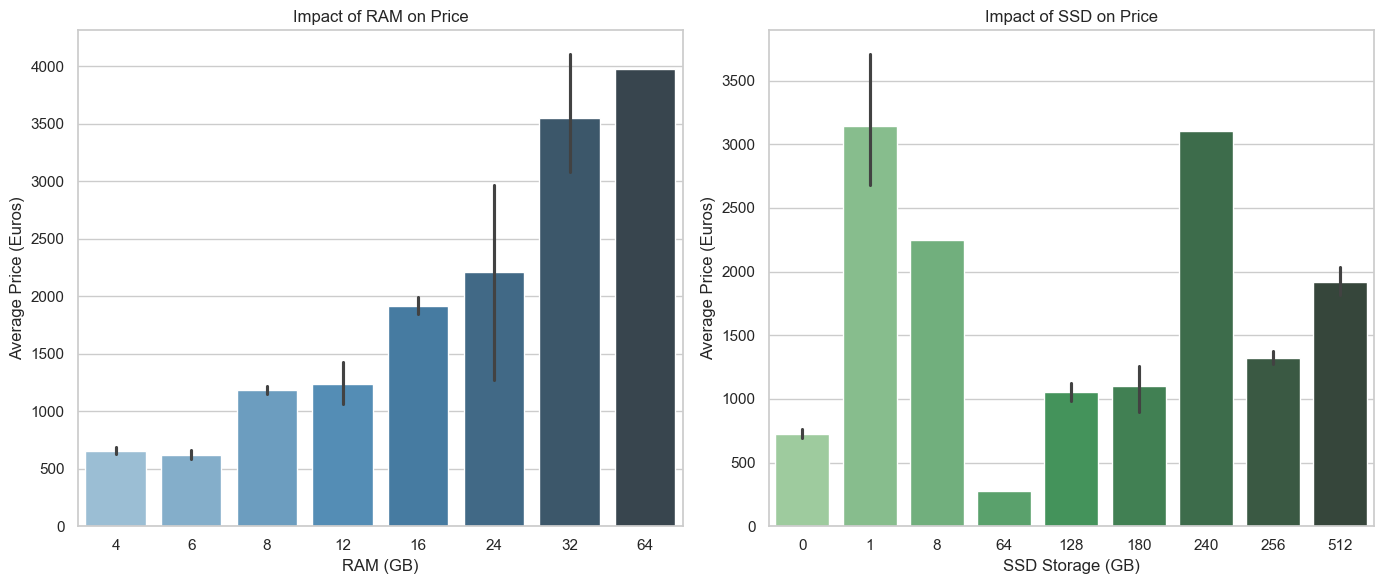

In [7]:
plt.figure(figsize=(14, 6))

# Subplot 1: RAM vs Price
plt.subplot(1, 2, 1)
sns.barplot(x='Ram', y='Price_euros', data=df, palette='Blues_d')
plt.title('Impact of RAM on Price')
plt.xlabel('RAM (GB)')
plt.ylabel('Average Price (Euros)')

# Subplot 2: SSD vs Price
plt.subplot(1, 2, 2)
sns.barplot(x='SSD', y='Price_euros', data=df, palette='Greens_d')
plt.title('Impact of SSD on Price')
plt.xlabel('SSD Storage (GB)')
plt.ylabel('Average Price (Euros)')

plt.tight_layout()
plt.show()

## 9. Analisi e Correzione dei Dati SSD

Dall'analisi visiva emerge un'incongruenza nella colonna `SSD`. Mentre il valore 0 indica correttamente l'assenza di tale componente, il valore **1** risulta associato alla fascia di prezzo più alta, indicando chiaramente che rappresenta **1 TB (1024 GB)** e non 1 GB. Mantenere il valore 1 falserebbe la relazione lineare tra capacità e prezzo. Inoltre, il valore **8** e **240** identificano due singoli record anomali che non contribuiscono alla capacità predittiva del modello.

Nella cella seguente procediamo alla normalizzazione dei valori e alla rimozione dell'outlier specifico per rendere coerente la scala delle feature.

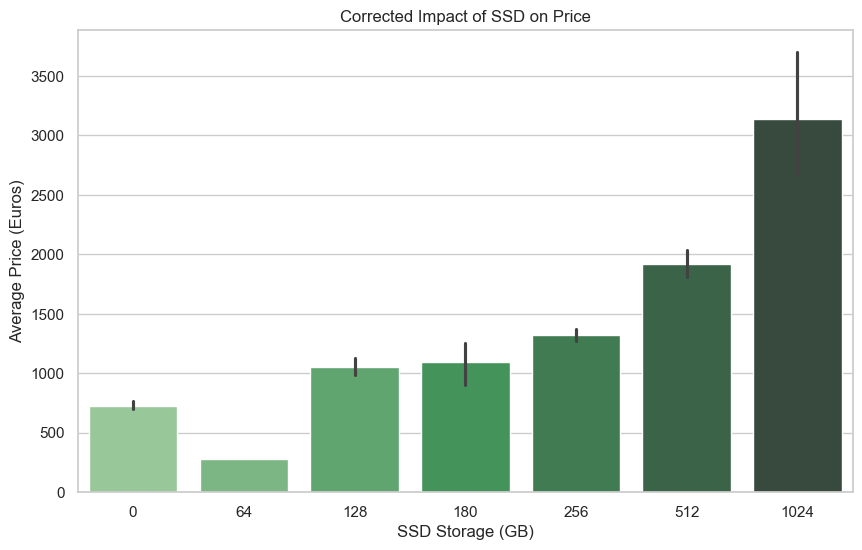

In [8]:
df.loc[df['SSD'] == 1, 'SSD'] = 1024

df = df[df['SSD'] != 8]
df = df[df['SSD'] != 240]

plt.figure(figsize=(10, 6))
sns.barplot(x='SSD', y='Price_euros', data=df, palette='Greens_d')
plt.title('Corrected Impact of SSD on Price')
plt.xlabel('SSD Storage (GB)')
plt.ylabel('Average Price (Euros)')
plt.show()

## 10. Gestione Outlier e High Leverage Points (HLP)

Per migliorare la capacità di generalizzazione dei modelli, è fondamentale gestire gli **outlier** e i **High Leverage Points** (punti con valori estremi nelle feature). Valori di prezzo eccessivamente alti (come i laptop da 6000€ identificati in precedenza) possono distorcere la pendenza della regressione, portando a errori sistematici sulla maggior parte delle previsioni.

Utilizziamo il metodo dell'**Interquartile Range (IQR)** per identificare e rimuovere le osservazioni che cadono fuori dai limiti statistici convenzionali sulla variabile target.

In [9]:
# Calculate IQR for Price_euros
Q1 = df['Price_euros'].quantile(0.25)
Q3 = df['Price_euros'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds for outlier detection
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filtering the dataset
df_clean = df[(df['Price_euros'] >= lower_bound) & (df['Price_euros'] <= upper_bound)]

print(f"Original shape: {df.shape}")
print(f"Shape after outlier removal: {df_clean.shape}")
print(f"Removed {df.shape[0] - df_clean.shape[0]} outliers")

# Update df to use cleaned data
df = df_clean.copy()

Original shape: (1144, 19)
Shape after outlier removal: (1112, 19)
Removed 32 outliers


## 11. Analisi di Correlazione

Con i dati numerici pronti e le nuove feature estratte, è fondamentale studiare le relazioni lineari all'interno del dataset. La matrice di correlazione ci permette di:

* **Identificare i principali predittori**: Individuare quali variabili (come `Ram` o `SSD`) hanno l'impatto più forte sul prezzo.
* **Rilevare la multicollinearità**: Individuare variabili fortemente correlate tra loro (come `X_res` e `Y_res`) che potrebbero destabilizzare i modelli lineari.
* **Escludere feature irrilevanti**: Notare variabili con correlazione quasi nulla rispetto al target.

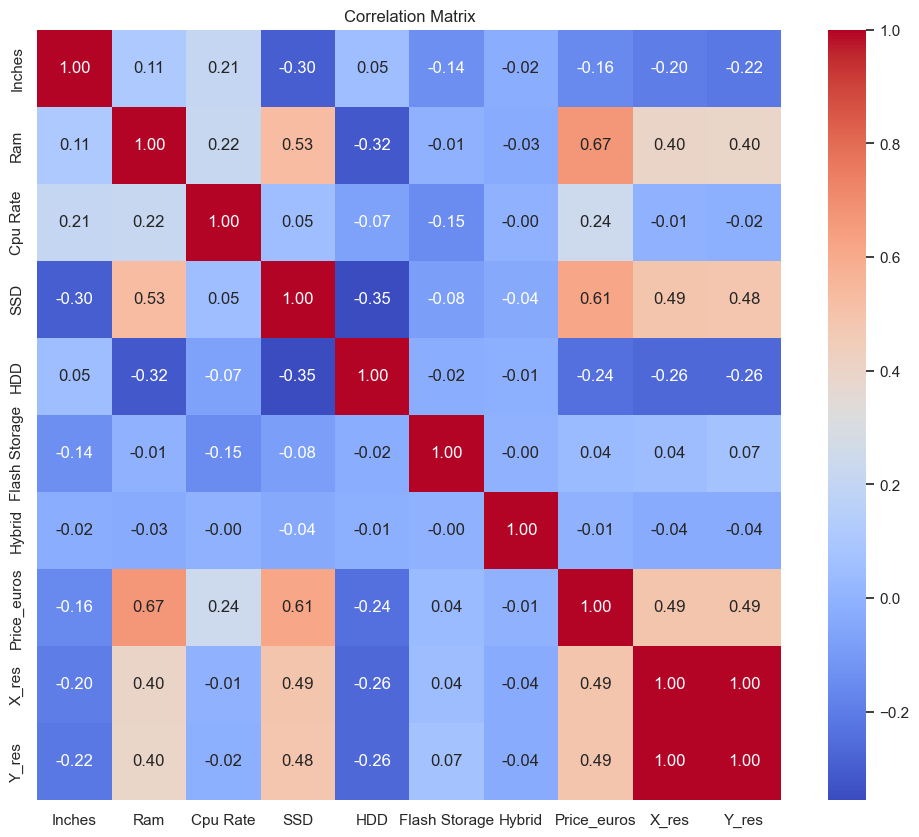

Price_euros      1.000000
Ram              0.670034
SSD              0.613962
Y_res            0.488864
X_res            0.487642
Cpu Rate         0.243976
Flash Storage    0.036602
Hybrid          -0.009048
Inches          -0.157669
HDD             -0.242440
Name: Price_euros, dtype: float64


In [10]:
plt.figure(figsize=(12, 10))
numeric_df = df.select_dtypes(include=['number'])
correlation = numeric_df.corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

# Print correlation with target variable
print(correlation['Price_euros'].sort_values(ascending=False))

## 12. Feature Engineering e Selezione

Dall'analisi della matrice di correlazione emergono spunti fondamentali:

* **Multicollinearità**: `X_res` e `Y_res` sono quasi perfettamente correlate, indicando ridondanza.
* **Feature Irrilevanti**: `Inches`, `Flash Storage` e `Hybrid` mostrano una correlazione vicina allo zero con il prezzo, agendo come puro rumore per i modelli.
* **Sintesi della qualità video**: Sebbene la dimensione fisica (`Inches`) sia poco influente, la risoluzione lo è. Possiamo combinare questi dati per creare una metrica di densità dei pixel più significativa.

Nella cella successiva, calcoliamo i **PPI (Pixels Per Inch)** per catturare la qualità dello schermo in un'unica variabile e procediamo alla rimozione delle feature ridondanti o deboli per migliorare la generalizzazione del modello.

Price_euros    1.000000
Ram            0.670034
SSD            0.613962
PPI            0.477588
Cpu Rate       0.243976
HDD           -0.242440
Name: Price_euros, dtype: float64


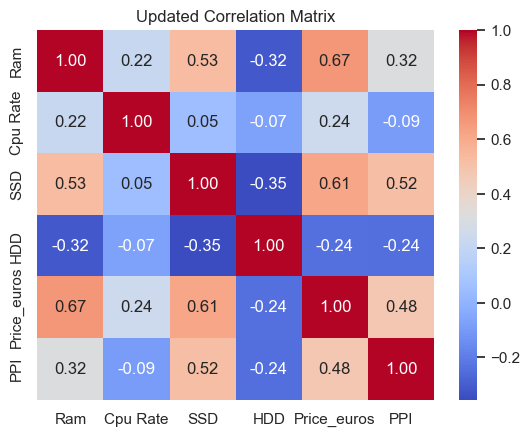

In [11]:
df['PPI'] = (((df['X_res']**2) + (df['Y_res']**2))**0.5) / df['Inches']

cols_to_drop = ['ScreenResolution', 'Inches', 'X_res', 'Y_res', 'Flash Storage', 'Hybrid']
df = df.drop(columns=cols_to_drop)

numeric_cols = df.select_dtypes(include=['number'])
print(numeric_cols.corr()['Price_euros'].sort_values(ascending=False))

sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Updated Correlation Matrix')
plt.show()

## 13. Encoding delle Variabili Categoriche

L'aggiornamento della matrice di correlazione conferma l'efficacia della nuova feature **PPI** () come predittore del prezzo. Per procedere con il training, dobbiamo trasformare le variabili testuali in numeriche:

* **Rimozione Product**: La colonna viene esclusa a causa dell'eccessiva cardinalità, che causerebbe overfitting e una dimensionalità troppo elevata.
* **One-Hot Encoding**: Applichiamo la codifica dummy alle restanti variabili categoriche, utilizzando `drop_first=True` per prevenire la multicollinearità tra le colonne generate.

Nella cella seguente generiamo il dataset finale per la fase di modellazione.

In [12]:
df = df.drop(columns=['Product'])

# One-Hot Encoding (con drop_first=True per evitare la "trappola delle dummy")
df_encoded = pd.get_dummies(df, drop_first=True)

print(f"Dataset Shape: {df_encoded.shape}")
df_encoded.head()

Dataset Shape: (1112, 185)


,Ram,Cpu Rate,SSD,HDD,Price_euros,PPI,Company_Apple,Company_Asus,Company_Dell,Company_Fujitsu,...,Gpu Model_Radeon R7 M440,Gpu Model_Radeon R7 M445,Gpu Model_Radeon R7 M460,Gpu Model_Radeon R7 M465,Gpu Model_Radeon R9 M385,Gpu Model_Radeon RX 540,Gpu Model_Radeon RX 550,Gpu Model_Radeon RX 560,Gpu Model_Radeon RX 580,Gpu Model_UHD Graphics 620
0,8,2.5,256,0,575.0,141.211998,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,4,3.0,0,500,400.0,100.454670,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,16,1.8,512,0,1495.0,157.350512,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
3,8,1.6,256,0,770.0,157.350512,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
4,4,2.5,0,500,393.9,100.454670,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


## 14. Train-Test Split

L'operazione di encoding ha portato il dataset a una dimensione di 195 feature. Data l'alta dimensionalità, la suddivisione corretta dei dati è fondamentale per validare la capacità di generalizzazione dei modelli ed evitare l'overfitting.

In questa cella separiamo il target dal set di feature e dividiamo i dati in **Training Set** (80%) e **Test Set** (20%), utilizzando il `SEED` configurato inizialmente per garantire la riproducibilità dei risultati.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_encoded.drop(columns=['Price_euros'])
y = df_encoded['Price_euros']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

print(f"Train set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Train set shape: (889, 184)
Test set shape: (223, 184)


## 15. Definizione delle Metriche di Valutazione

Per confrontare oggettivamente le performance dei modelli, è necessario utilizzare diverse metriche che forniscano una visione complementare della precisione delle stime:

* **Score**: misura la proporzione di varianza dei prezzi spiegata dal modello.
* **MAE (Mean Absolute Error)**: rappresenta l'errore medio in termini monetari (euro), rendendo i risultati facilmente interpretabili.
* **RMSE (Root Mean Squared Error)**: fornisce una misura dell'errore che penalizza maggiormente gli scarti più grandi, utile per identificare modelli che commettono errori grossolani su laptop di fascia alta o molto economica.

Definiamo ora una funzione di supporto per standardizzare la valutazione di tutti i modelli che andremo ad addestrare.

Prima definisco una funzione utile per dopo

In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def evaluate_model(model, X_test, y_test, model_name="Model"):
    # Generate predictions
    y_pred = model.predict(X_test)
    
    # Calculate metrics
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse) 
    
    # Print formatted results
    print(f"--- {model_name} Performance ---")
    print(f"R2 Score: {r2:.4f}")
    print(f"MAE:      {mae:.2f} euros")
    print(f"RMSE:     {rmse:.2f} euros")
    print("-" * 35)
    
    return r2, mae, rmse

## 16. Linear Regression (Baseline)

Come primo modello addestriamo una **Regressione Lineare** per stabilire una baseline di performance. Per garantire un corretto preprocessing senza incorrere in data leakage, utilizziamo una `Pipeline` che integra lo `StandardScaler` e il modello. Verifichiamo inoltre la stabilità dei risultati tramite **Cross-Validation** su 5 fold prima della valutazione finale sul test set.

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

# Pipeline: StandardScaler + LinearRegression
lin_reg_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

# Train
lin_reg_pipe.fit(X_train, y_train)

# Cross Validation to check stability
cv_scores = cross_val_score(lin_reg_pipe, X_train, y_train, cv=5, scoring='r2')

print(f"Average CV R2: {cv_scores.mean():.4f}")

# Final evaluation
lr_r2, lr_mae, lr_rmse = evaluate_model(lin_reg_pipe, X_test, y_test, "Linear Regression")

Average CV R2: 0.7461
--- Linear Regression Performance ---
R2 Score: 0.7469
MAE:      209.97 euros
RMSE:     278.04 euros
-----------------------------------


## 17. Lasso Regression (L1) con Hyperparameter Tuning

La **Regressione Lasso** introduce una regolarizzazione di tipo L1 che, oltre a prevenire l'overfitting, può azzerare i coefficienti delle feature meno rilevanti, effettuando una selezione automatica delle variabili in un dataset ad alta dimensionalità (194 feature).

In questa cella:

* Utilizziamo una **Pipeline** per garantire che lo scaling dei dati avvenga correttamente all'interno di ogni fold della Cross-Validation.
* Eseguiamo una **GridSearchCV** per individuare il valore ottimale del parametro di regolarizzazione `alpha`.
* Aumentiamo `max_iter` e la tolleranza per assicurare la convergenza del modello anche con valori di alpha molto bassi.

In [16]:
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV

# Pipeline: StandardScaler + Lasso
lasso_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Lasso(max_iter=50000, tol=0.01))
])

# Grid Search for alpha
lasso_params = {'model__alpha': [0.001, 0.01, 0.1, 1, 10, 100]}
lasso_grid = GridSearchCV(lasso_pipe, lasso_params, cv=5, scoring='r2', n_jobs=-1)

# Train
lasso_grid.fit(X_train, y_train)

print(f"Best Lasso Parameters: {lasso_grid.best_params_}")
print(f"Best CV R2: {lasso_grid.best_score_:.4f}")

# Final evaluation
lasso_r2, lasso_mae, lasso_rmse = evaluate_model(lasso_grid, X_test, y_test, "Lasso (L1)")

Best Lasso Parameters: {'model__alpha': 10}
Best CV R2: 0.7648
--- Lasso (L1) Performance ---
R2 Score: 0.7467
MAE:      210.47 euros
RMSE:     278.19 euros
-----------------------------------


## 18. Ridge Regression (L2) con Hyperparameter Tuning

La **Regressione Ridge** introduce una regolarizzazione di tipo L2 che penalizza i coefficienti elevati riducendone l'entità senza però annullarli completamente. È particolarmente efficace in presenza di multicollinearità, situazione probabile data l'alta dimensionalità raggiunta dopo l'encoding delle variabili categoriche.

Utilizziamo nuovamente una **Pipeline** accoppiata a **GridSearchCV** per testare un ampio range di valori del parametro `alpha`, cercando il punto di equilibrio ottimale tra distorsione (*bias*) e varianza.

In [17]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

# Pipeline: StandardScaler + Ridge
ridge_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Ridge(random_state=SEED))
])

# Grid Search for alpha
ridge_params = {'model__alpha': [0.1, 1, 10, 100, 200, 500, 1000]}

ridge_grid = GridSearchCV(ridge_pipe, ridge_params, cv=5, scoring='r2', n_jobs=-1)

# Train
ridge_grid.fit(X_train, y_train)

print(f"Best Ridge Parameters: {ridge_grid.best_params_}")
print(f"Best CV R2: {ridge_grid.best_score_:.4f}")

# Final evaluation
ridge_r2, ridge_mae, ridge_rmse = evaluate_model(ridge_grid, X_test, y_test, "Ridge (L2)")

Best Ridge Parameters: {'model__alpha': 100}
Best CV R2: 0.7640
--- Ridge (L2) Performance ---
R2 Score: 0.7473
MAE:      209.57 euros
RMSE:     277.83 euros
-----------------------------------


## 19. MLP Regressor (Neural Network)

Con l'**MLPRegressor** passiamo da modelli lineari a un approccio basato su **Reti Neurali Artificiali**. L'obiettivo è verificare se il modello è in grado di catturare relazioni non lineari più complesse tra le feature e il prezzo che potrebbero essere sfuggite ai modelli precedenti.

In questa cella:

* Definiamo una **Pipeline** per scalare i dati, operazione fondamentale per la convergenza delle reti neurali.
* Utilizziamo **GridSearchCV** per testare diverse architetture (numero di layer e neuroni), la regolarizzazione (`alpha`) e il tasso di apprendimento iniziale.
* Impostiamo un numero elevato di iterazioni per garantire che la rete raggiunga la convergenza.

In [18]:
from sklearn.neural_network import MLPRegressor

# Pipeline: StandardScaler + MLP
mlp_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', MLPRegressor(max_iter=2000, random_state=SEED))
])

# Grid Search for architecture and hyperparameters
mlp_params = {
    'model__hidden_layer_sizes': [(64, 32), (100, 50), (128, 64, 32)],
    'model__alpha': [0.0001, 0.001, 0.01, 0.1],
    'model__learning_rate_init': [0.001, 0.01]
}

mlp_grid = GridSearchCV(mlp_pipe, mlp_params, cv=3, scoring='r2', n_jobs=-1)

# Train
mlp_grid.fit(X_train, y_train)

print(f"Best MLP Parameters: {mlp_grid.best_params_}")
print(f"Best CV R2: {mlp_grid.best_score_:.4f}")

# Final evaluation
mlp_r2, mlp_mae, mlp_rmse = evaluate_model(mlp_grid, X_test, y_test, "MLP Perceptron")

Best MLP Parameters: {'model__alpha': 0.001, 'model__hidden_layer_sizes': (64, 32), 'model__learning_rate_init': 0.001}
Best CV R2: 0.7633
--- MLP Perceptron Performance ---
R2 Score: 0.7066
MAE:      200.62 euros
RMSE:     299.38 euros
-----------------------------------


## 20. Visualizzazione delle Performance dei Modelli

Per consolidare i risultati ottenuti, procediamo con una visualizzazione grafica delle metriche. Il confronto si focalizza su due aspetti:

* **Score**: Indica la capacità del modello di spiegare la variabilità dei dati (più alto è meglio).
* **MAE e RMSE**: Rappresentano l'errore medio in euro. Un RMSE significativamente più alto del MAE indicherebbe la presenza di errori di grande entità su alcuni specifici laptop.

Questa analisi visiva permette di identificare immediatamente il modello più bilanciato per l'implementazione finale.


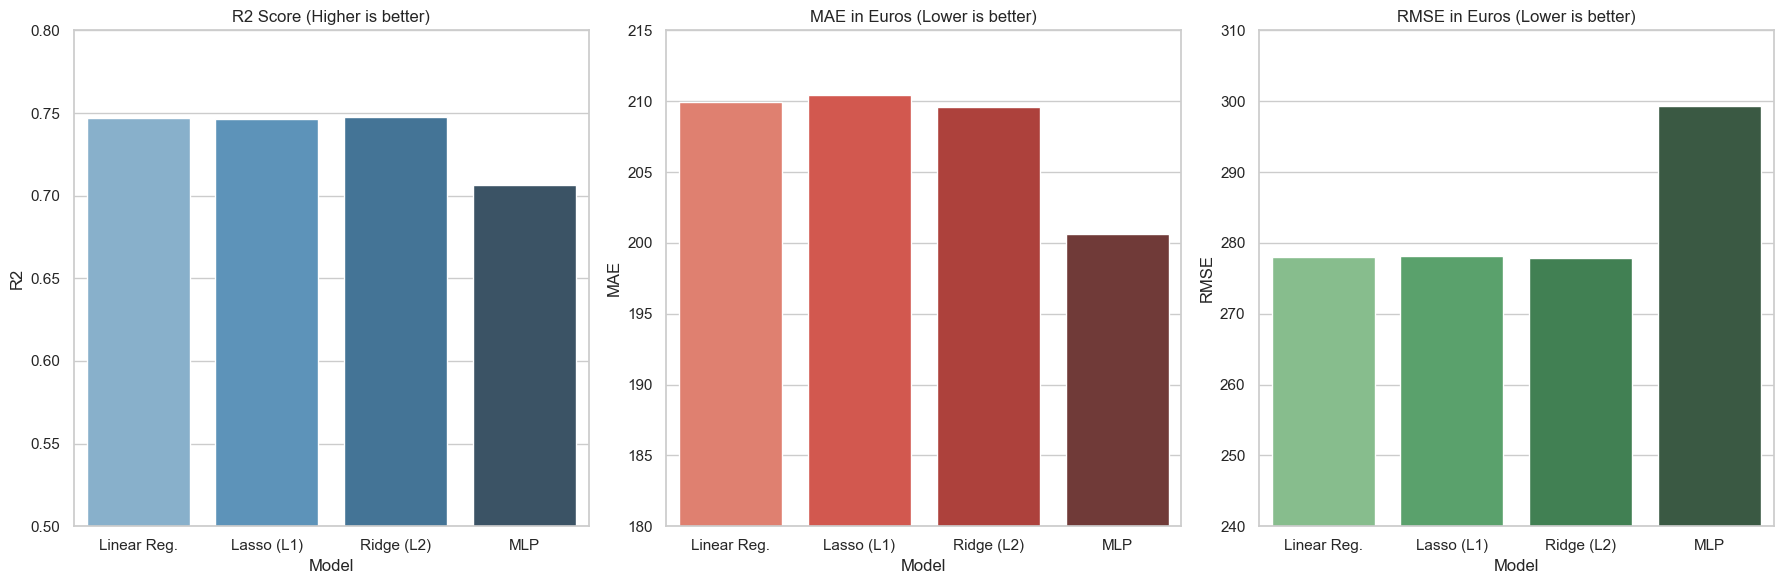

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

results_data = {
    'Model': ['Linear Reg.', 'Lasso (L1)', 'Ridge (L2)', 'MLP'],
    'R2': [lr_r2, lasso_r2, ridge_r2, mlp_r2],
    'MAE': [lr_mae, lasso_mae, ridge_mae, mlp_mae],
    'RMSE': [lr_rmse, lasso_rmse, ridge_rmse, mlp_rmse]
}
results_df = pd.DataFrame(results_data)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# R2 Score Plot - Focus on the top range
sns.barplot(x='Model', y='R2', data=results_df, ax=axes[0], palette='Blues_d')
axes[0].set_title('R2 Score (Higher is better)')
axes[0].set_ylim(0.50, 0.80)

# MAE Plot - Focus on the error range
sns.barplot(x='Model', y='MAE', data=results_df, ax=axes[1], palette='Reds_d')
axes[1].set_title('MAE in Euros (Lower is better)')
axes[1].set_ylim(180, 215)

# RMSE Plot - Focus on the error range
sns.barplot(x='Model', y='RMSE', data=results_df, ax=axes[2], palette='Greens_d')
axes[2].set_title('RMSE in Euros (Lower is better)')
axes[2].set_ylim(240, 310)

plt.tight_layout()
plt.show()

## 21. Analisi Finale delle Performance

In questa fase finale valutiamo l'efficacia dei modelli addestrati sul dataset processato. Grazie alla correzione della feature `SSD`, alla gestione degli outlier e alla creazione dei `PPI`, i modelli lavorano su dati puliti e coerenti, permettendoci di ottenere stime realistiche del valore di mercato dei laptop.

### Analisi dei Risultati

* **Performance Globali**: Tutti i modelli lineari (**Linear**, **Lasso**, **Ridge**) mostrano risultati estremamente solidi e convergenti, con un R^2 che si attesta stabilmente intorno a **0.747**. Questo conferma che la relazione tra le specifiche tecniche (RAM, Storage, Qualità dello schermo) e il prezzo è ben catturata da approcci basati sulla regressione.
* **Il Modello Migliore (Ridge Regression)**: Con un R^2 di **0.7473** e il MAE più basso tra i modelli lineari (**209.57 €**), la regressione Ridge si dimostra la soluzione più equilibrata. La regolarizzazione L2 è risultata fondamentale per gestire con precisione l'alta dimensionalità delle 194 feature generate senza incorrere in overfitting.
* **Il Caso del MLP (Rete Neurale)**: Il Perceptron mostra un comportamento peculiare: ottiene il **MAE più basso** in assoluto (**200.62 €**), indicando una grande precisione sulla maggior parte dei casi. Tuttavia, presenta l'**RMSE più alto** (**299.38 €**), segno che il modello fatica a gestire alcuni laptop con configurazioni particolari, commettendo errori più marcati rispetto ai modelli lineari.

### Sintesi Tecnica

Il progetto si conclude con un modello in grado di stimare il prezzo di un laptop con un errore medio di circa **210 euro**. Data la complessità del mercato e la varianza dei prezzi (che vanno dai 265€ ai 2800€), il risultato è molto soddisfacente. Il modello **Ridge** è quello consigliato per la produzione grazie alla sua robustezza e alla costanza nelle performance su tutto il dataset.